
Circuit A
Prediction: 1
Actual counts: {'1': 100}


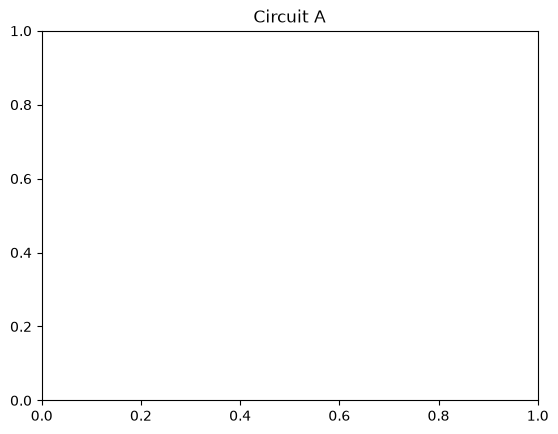


Circuit B
Prediction: 0
Actual counts: {'0': 100}


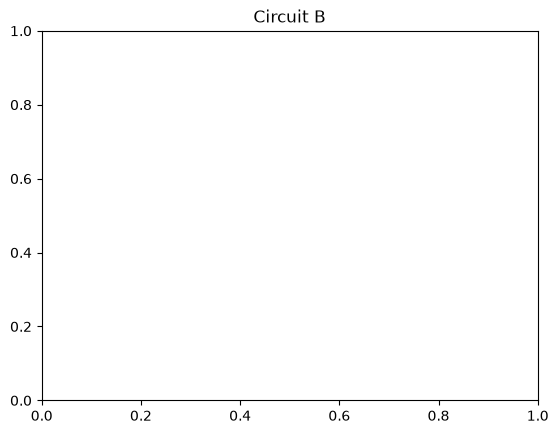


Circuit C
Prediction: 0 and 1 approximately equally
Actual counts: {'0': 44, '1': 56}


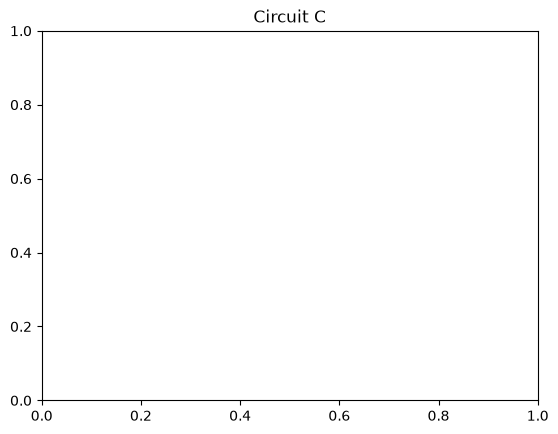


Comparison of predictions and actual results:
Circuit A -> {'1': 100}
Circuit B -> {'0': 100}
Circuit C -> {'0': 44, '1': 56}


In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

simulator = AerSimulator()

# Circuit A: One X gate
qc_a = QuantumCircuit(1, 1)
qc_a.x(0)
qc_a.measure(0, 0)

# Circuit B: Two X gates
qc_b = QuantumCircuit(1, 1)
qc_b.x(0)
qc_b.x(0)
qc_b.measure(0, 0)

# Circuit C: One H gate
qc_c = QuantumCircuit(1, 1)
qc_c.h(0)
qc_c.measure(0, 0)

# Run each circuit for 100 shots
circuits = [qc_a, qc_b, qc_c]
names = ["Circuit A", "Circuit B", "Circuit C"]
predictions = ["1", "0", "0 and 1 approximately equally"]

results = {}

for name, circuit, prediction in zip(names, circuits, predictions):
    job = simulator.run(circuit, shots=100)
    counts = job.result().get_counts()
    results[name] = counts

    print(f"\n{name}")
    print("Prediction:", prediction)
    print("Actual counts:", counts)

    plot_histogram(counts)
    plt.title(name)
    plt.show()

print("\nComparison of predictions and actual results:")
for name in names:
    print(name, "->", results[name])